<div align="center" style="text-align:center; padding:24px 0 16px;">

<h1 style="font-size:2.4em; margin-bottom:0.2em;">Selection of Candidate Models</h1>

<h3 style="font-weight:400; margin-top:0;">easyJet Flight Delays at London Gatwick Airport</h3>

<p style="margin:12px 0 4px;"><b>Course:</b> Time Series and Forecasting - 2026/2027</p>

<p style="margin:18px 0 4px;"><b>Authors</b></p>
<p style="margin:0; line-height:1.6;">
Joana Ferreira (up202305202)<br>
Leonor Baía (up202304808)<br>
Mariana Bissacot (up202306832)<br>
Rita Nunes (up202305232)
</p>

</div>

<br>

## Research question

> **Can we forecast the monthly average departure delay of easyJet flights at London Gatwick Airport?**

This notebook continues directly from **Deliverable 1**. The data preparation and exploratory analysis have already been completed, so they are not repeated here.

The purpose of this notebook is:

> **Given the characteristics already observed in the series, which time-series models are defensible candidates for the forecasting stage?**

### Scope of this notebook

The following tasks were completed in the first notebook:

- raw CAA file consolidation and schema harmonisation;
- construction of the flight-weighted monthly target;
- data-quality and temporal-coverage analysis;
- time plots and dynamics;
- trend and seasonality analysis;
- Box–Cox transformation assessment;
- STL decomposition;
- ACF-based temporal-dependence analysis;
- easyJet vs. other-airline and route-level exploratory analyses.

This notebook therefore focuses only on the **model-selection stage**.

<div align="center">

**EDA findings** → **Stationarity decision** → **ACF/PACF identification** → **Candidate models**  
↓  
**COVID intervention** → **Model fitting** → **Diagnostics** → **Candidate selection**

</div>



## 1. Input handed over from Deliverable 1

The input to this notebook is the **model-ready monthly series** produced in Deliverable 1.

Expected file: `easyjet_gatwick_monthly.csv`

Expected columns:
- `date`
- `average_delay_mins`
- `flights_matched`
- `routes`
- `countries`

Only a compact integrity check is performed here. Data preparation is not repeated.


In [1]:

from pathlib import Path
import warnings
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


In [2]:

# Put easyjet_gatwick_monthly.csv in the same folder as this notebook.
candidate_paths = [
    Path("easyjet_gatwick_monthly.csv"),
    Path("dados_consolidados/easyjet_gatwick_monthly.csv"),
    Path("../easyjet_gatwick_monthly.csv")
]

DATA_PATH = next((p for p in candidate_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "easyjet_gatwick_monthly.csv was not found. Export the monthly model-ready series "
        "from Deliverable 1 and place it next to this notebook."
    )

monthly = (
    pd.read_csv(DATA_PATH, parse_dates=["date"])
      .set_index("date")
      .sort_index()
      .asfreq("MS")
)

y = monthly["average_delay_mins"].astype(float)

print(f"Input file: {DATA_PATH}")
print(f"Calendar period: {y.index.min():%b %Y} – {y.index.max():%b %Y}")
print(f"Calendar months: {len(y)}")
print(f"Valid target observations: {y.notna().sum()}")
print("Missing target months:", list(y[y.isna()].index.strftime("%Y-%m")))


Input file: dados_consolidados\easyjet_gatwick_monthly.csv
Calendar period: Jan 2001 – Jul 2026
Calendar months: 307
Valid target observations: 305
Missing target months: ['2020-04', '2020-05']



## 2. Modelling requirements inherited from the EDA

Deliverable 1 already established the features that matter for model choice:

1. **Annual seasonality** with period 12.
2. **Short-term dependence**, especially at the first few lags.
3. **Annual dependence** around lag 12.
4. **Changing long-run level**, but not a stable straight-line trend.
5. **Changing variance**, with larger fluctuations in high-delay regimes.
6. **COVID-19 as an exceptional structural regime**, not normal seasonality.
7. April and May 2020 are structurally missing because no matched easyJet flights operated.

These findings imply that the candidate set should contain:
- a seasonal benchmark;
- a stationary seasonal ARMA alternative;
- seasonal ARIMA models;
- intervention models that explicitly represent COVID;
- only if justified, a later variance model such as GARCH.

The aim is **parsimony**: keep enough structure to explain the dependence, but avoid adding parameters that do not improve the model.



# 3. Stationarity and differencing decision

Deliverable 1 inspected differenced series visually; here we formalise the decision using **ADF and KPSS**.

The two tests have opposite null hypotheses:

### Augmented Dickey–Fuller (ADF)

$$
H_0:\ \text{the series contains a unit root}
$$

A small p-value provides evidence **against** a unit root.

### KPSS

$$
H_0:\ \text{the series is stationary}
$$

A small p-value provides evidence **against** stationarity.

We use a temporary interpolated copy only because ADF/KPSS require complete data. The interpolation covers **only April–May 2020** and is **never used as the observed target for model fitting**.


In [3]:

# Diagnostic copy only: interpolate the two structurally missing months.
y_diag = y.interpolate(method="time", limit=2)

def run_stationarity_tests(series, label, adf_reg="c", kpss_reg="c"):
    s = series.dropna()

    adf_res = adfuller(s, regression=adf_reg, autolag="AIC")
    kpss_res = kpss(s, regression=kpss_reg, nlags="auto")

    return {
        "Series": label,
        "n": len(s),
        "ADF reg.": adf_reg,
        "ADF statistic": adf_res[0],
        "ADF p-value": adf_res[1],
        "KPSS reg.": kpss_reg,
        "KPSS statistic": kpss_res[0],
        "KPSS p-value": kpss_res[1],
    }

tests = []

# Original series: test both level-stationarity and trend-stationarity specifications.
tests.append(run_stationarity_tests(y_diag, "Original — level test", "c", "c"))
tests.append(run_stationarity_tests(y_diag, "Original — trend test", "ct", "ct"))

# Differenced series: a constant is the natural specification.
tests.append(run_stationarity_tests(y_diag.diff(), "First difference", "c", "c"))
tests.append(run_stationarity_tests(y_diag.diff(12), "Seasonal difference (12)", "c", "c"))
tests.append(run_stationarity_tests(
    y_diag.diff().diff(12), "First + seasonal difference", "c", "c"
))

stationarity_table = pd.DataFrame(tests)
display(stationarity_table.round(4))


,Series,n,ADF reg.,ADF statistic,ADF p-value,KPSS reg.,KPSS statistic,KPSS p-value
0,Original — level test,307,c,-3.898,0.002,c,0.099,0.100
1,Original — trend test,307,ct,-3.923,0.011,ct,0.061,0.100
2,First difference,306,c,-4.901,0.000,c,0.013,0.100
3,Seasonal difference (12),295,c,-4.366,0.000,c,0.032,0.100
4,First + seasonal difference,294,c,-7.043,0.000,c,0.016,0.100



### Interpretation rule

The tests are **evidence**, not an automatic model selector.

A structural break can make unit-root tests difficult to interpret, and the EDA already showed a major 2020–2021 regime change. Therefore:

- if the original series appears stationary by ADF/KPSS, we should retain at least one **non-differenced seasonal ARMA** candidate;
- because the EDA showed changing level and strong seasonal persistence, we should also retain **SARIMA candidates with differencing**;
- the comparison between these two families will be settled using fit, residual diagnostics and a preliminary holdout check.

This avoids imposing $d=1$ and $D=1$ simply because SARIMA is familiar.



# 4. ACF and PACF for candidate identification

Deliverable 1 already examined the ACF. Here we add the **PACF** because model identification depends on both:

- **AR(p):** ACF tends to decay; PACF tends to cut off after $p$.
- **MA(q):** ACF tends to cut off after $q$; PACF tends to decay.
- **ARMA:** both generally decay.
- seasonal spikes at 12, 24, ... indicate seasonal AR/MA structure.

We inspect:
1. the original series;
2. the first + seasonal differenced series.

The second view is especially useful for identifying a parsimonious SARIMA structure.


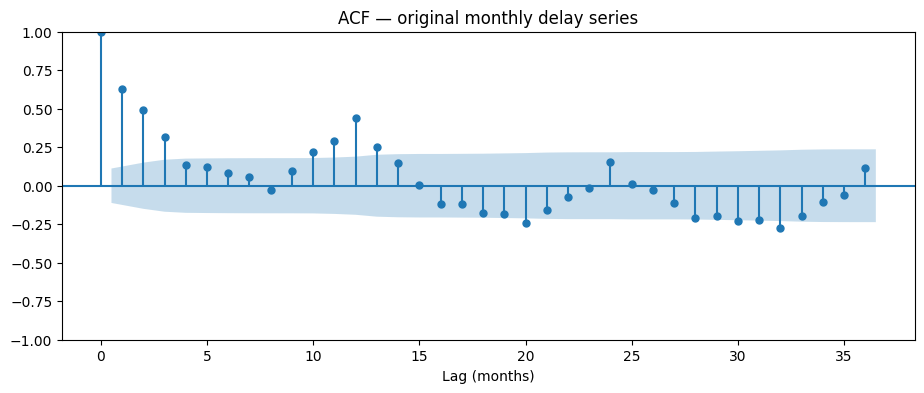

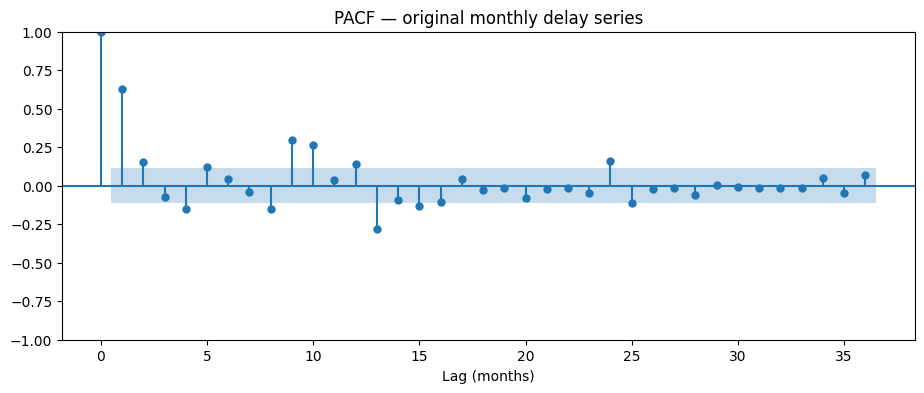

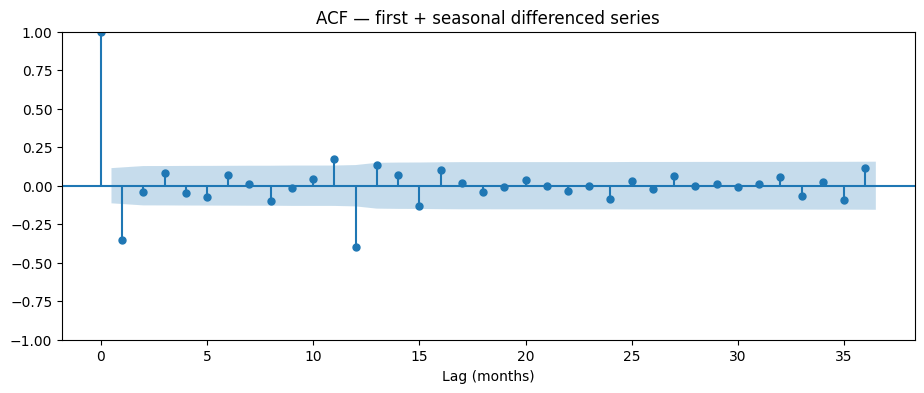

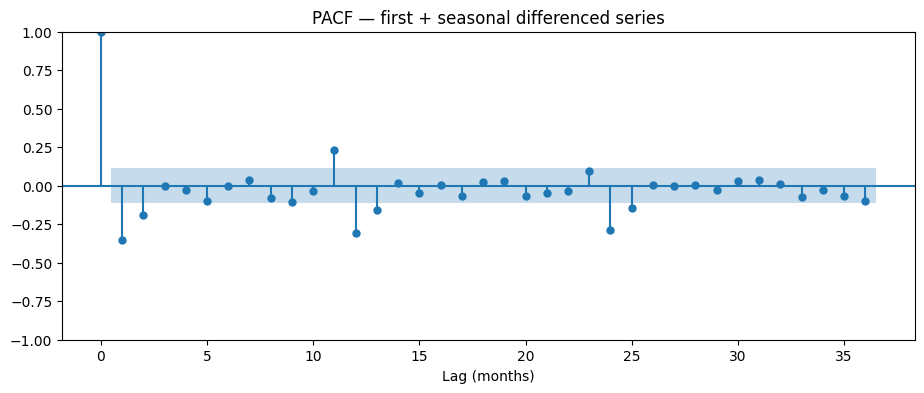

In [4]:

def plot_acf_pacf(series, title, lags=36):
    s = series.dropna()

    fig, ax = plt.subplots(figsize=(11, 4))
    plot_acf(s, lags=lags, ax=ax)
    ax.set_title(f"ACF — {title}")
    ax.set_xlabel("Lag (months)")
    plt.show()

    fig, ax = plt.subplots(figsize=(11, 4))
    plot_pacf(s, lags=lags, ax=ax, method="ywm")
    ax.set_title(f"PACF — {title}")
    ax.set_xlabel("Lag (months)")
    plt.show()

plot_acf_pacf(y_diag, "original monthly delay series")
plot_acf_pacf(y_diag.diff().diff(12), "first + seasonal differenced series")


In [5]:

# Compact numerical evidence for the written justification.
def selected_dependence(series, label, lags=(1, 2, 3, 12, 24, 36)):
    s = series.dropna()
    a = acf(s, nlags=max(lags), fft=False)
    p = pacf(s, nlags=max(lags), method="ywm")
    return pd.DataFrame({
        "Series": label,
        "Lag": lags,
        "ACF": [a[k] for k in lags],
        "PACF": [p[k] for k in lags],
    })

dependence_table = pd.concat([
    selected_dependence(y_diag, "Original"),
    selected_dependence(y_diag.diff().diff(12), "First + seasonal diff."),
], ignore_index=True)

display(dependence_table.round(3))


,Series,Lag,ACF,PACF
0,Original,1,0.631,0.631
1,Original,2,0.491,0.154
2,Original,3,0.317,-0.072
3,Original,12,0.439,0.139
4,Original,24,0.153,0.163
5,Original,36,0.113,0.070
6,First + seasonal diff.,1,-0.353,-0.353
7,First + seasonal diff.,2,-0.040,-0.189
8,First + seasonal diff.,3,0.082,-0.002
9,First + seasonal diff.,12,-0.398,-0.308



### Model-identification reading

The EDA showed strong short-term persistence and an annual echo in the original series.

After first and seasonal differencing, the most relevant remaining dependence is concentrated around:

- **lag 1** → possible non-seasonal MA(1) and/or low-order AR structure;
- **lag 12** → possible seasonal MA(1) and/or seasonal AR structure.

This makes the following model a natural **starting candidate**:

$$
\boxed{\text{SARIMA}(0,1,1)\times(0,1,1)_{12}}
$$

It is not assumed to be the final model. We also retain:

- a non-differenced SARMA alternative;
- slightly richer AR structures if residual dependence remains.



# 5. COVID-19: explicit intervention strategy

The pandemic must be handled explicitly because it is not ordinary seasonal behaviour.

## 5.1 Three distinct data situations

### April–May 2020

No matched easyJet departures operated, so the monthly average delay is **undefined**:

$$
Y_t = \mathrm{NaN}
$$

These months remain missing during model fitting. They are **not** replaced by zero.

### Other months in 2020–2021

The observed delays are real, but they come from an exceptional operating regime.

### Post-COVID

The rebound from 2022 is also unusual, but these are genuine observations and should not simply be discarded.

---

## 5.2 COVID specifications tested

We compare three approaches:

**A. No intervention**  
The ARIMA dynamics must absorb the pandemic themselves.

**B. One COVID-regime dummy**  
March 2020–December 2021 receives one intervention indicator.

**C. Two-stage COVID intervention**  
Separate indicators are used for:

- March–December 2020;
- January–December 2021.

This tests whether the acute disruption and the partial recovery should have different average effects.

A fourth specification — masking the full COVID regime — is used **only as a sensitivity analysis**, not as the primary model.

> **Important:** AIC/BIC from the masked model are not directly comparable with full-sample models because the effective estimation samples differ.


In [6]:

interventions = pd.DataFrame(index=y.index)

interventions["covid_regime"] = (
    (interventions.index >= "2020-03-01")
    & (interventions.index <= "2021-12-01")
).astype(int)

interventions["covid_2020"] = (
    (interventions.index >= "2020-03-01")
    & (interventions.index <= "2020-12-01")
).astype(int)

interventions["covid_2021"] = (
    (interventions.index >= "2021-01-01")
    & (interventions.index <= "2021-12-01")
).astype(int)

display(interventions.loc["2019-10-01":"2022-03-01"].T)


date,2019-10-01,2019-11-01,2019-12-01,2020-01-01,2020-02-01,2020-03-01,2020-04-01,2020-05-01,2020-06-01,2020-07-01,2020-08-01,2020-09-01,2020-10-01,2020-11-01,2020-12-01,2021-01-01,2021-02-01,2021-03-01,2021-04-01,2021-05-01,2021-06-01,2021-07-01,2021-08-01,2021-09-01,2021-10-01,2021-11-01,2021-12-01,2022-01-01,2022-02-01,2022-03-01
covid_regime,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0
covid_2020,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
covid_2021,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0



# 6. Candidate-model shortlist

The shortlist is intentionally small and theory-driven.

| ID | Candidate | Purpose |
|---|---|---|
| **B0** | Seasonal naïve | Benchmark: $\hat{Y}_t = Y_{t-12}$ |
| **M1** | SARMA$(1,0,1)\times(1,0,1)_{12}$ | Tests whether differencing is actually necessary |
| **M2** | SARIMA$(0,1,1)\times(0,1,1)_{12}$ | Parsimonious model suggested by the differenced ACF/PACF |
| **M3** | SARIMA$(1,1,1)\times(0,1,1)_{12}$ | Adds one short-term AR effect |
| **M4** | SARIMA$(2,1,1)\times(0,1,1)_{12}$ | Tests whether richer short-term memory improves residuals |
| **M5** | M2 + COVID dummy | Parsimonious intervention model |
| **M6** | M4 + COVID dummy | Richer intervention model |

The two-stage COVID intervention is analysed separately as a sensitivity refinement.

We do **not** fit a large unrestricted grid at this stage. The aim is to justify a small number of interpretable candidates and avoid over-parameterisation.



# 7. Fitting and preliminary evaluation design

Candidate selection should not be based on AIC alone.

We therefore use three types of evidence:

### 1. Information criteria
- AIC
- AICc
- BIC

Lower is better **only when models use the same response scale and effective sample**.

### 2. Residual diagnostics
- Ljung–Box at lags 12 and 24;
- ARCH-LM;
- Jarque–Bera;
- residual ACF.

A candidate should ideally leave no systematic serial correlation.

### 3. Preliminary 12-month holdout
Training ends in **July 2025** and the holdout is **August 2025–July 2026**.

Metrics:
- MAE
- RMSE

This is a **screening check**, not the final forecasting evaluation for the project.


In [7]:

TEST_START = pd.Timestamp("2025-08-01")

train = y.loc[: TEST_START - pd.offsets.MonthBegin(1)].copy()
test = y.loc[TEST_START:].copy()

print(f"Training period: {train.index.min():%b %Y} – {train.index.max():%b %Y}")
print(f"Holdout period:  {test.index.min():%b %Y} – {test.index.max():%b %Y}")
print(f"Holdout months:  {len(test)}")


Training period: Jan 2001 – Jul 2025
Holdout period:  Aug 2025 – Jul 2026
Holdout months:  12


In [8]:

def aicc(fit):
    k = len(fit.params)
    n = fit.nobs
    return fit.aic + (2 * k * (k + 1)) / (n - k - 1)

def forecast_metrics(actual, predicted):
    z = pd.concat(
        [actual.rename("actual"), predicted.rename("predicted")],
        axis=1
    ).dropna()

    err = z["actual"] - z["predicted"]

    return {
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err**2)),
    }

def residual_diagnostics(fit, index, burn=24):
    resid = pd.Series(fit.resid, index=index).dropna()

    if len(resid) > burn:
        resid = resid.iloc[burn:]

    lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
    arch_stat, arch_p, _, _ = het_arch(resid, nlags=12)
    jb = jarque_bera(resid)

    return {
        "LB p(12)": lb.loc[12, "lb_pvalue"],
        "LB p(24)": lb.loc[24, "lb_pvalue"],
        "ARCH-LM p": arch_p,
        "JB p": jb.pvalue,
    }

def fit_candidate(
    name,
    order,
    seasonal_order,
    trend="n",
    exog_cols=None,
    y_train=None,
):
    if y_train is None:
        y_train = train

    ex_train = None
    ex_test = None

    if exog_cols:
        ex_train = interventions.loc[y_train.index, exog_cols]
        ex_test = interventions.loc[test.index, exog_cols]

    model = SARIMAX(
        y_train,
        order=order,
        seasonal_order=seasonal_order,
        trend=trend,
        exog=ex_train,
        enforce_stationarity=True,
        enforce_invertibility=True,
        simple_differencing=False,
    )

    fit = model.fit(disp=False, maxiter=500)

    fc = fit.get_forecast(
        steps=len(test),
        exog=ex_test
    ).predicted_mean

    fc.index = test.index

    metrics = forecast_metrics(test, fc)
    diag = residual_diagnostics(fit, y_train.index)

    row = {
        "Model": name,
        "AIC": fit.aic,
        "AICc": aicc(fit),
        "BIC": fit.bic,
        **metrics,
        **diag,
        "Converged": bool(fit.mle_retvals.get("converged", True)),
    }

    return fit, fc, row



# 8. Fit the benchmark and core candidates


In [9]:

# Seasonal-naive benchmark.
seasonal_naive = y.shift(12).loc[test.index]
benchmark_metrics = forecast_metrics(test, seasonal_naive)

results = [{
    "Model": "B0 Seasonal naive",
    "AIC": np.nan,
    "AICc": np.nan,
    "BIC": np.nan,
    **benchmark_metrics,
    "LB p(12)": np.nan,
    "LB p(24)": np.nan,
    "ARCH-LM p": np.nan,
    "JB p": np.nan,
    "Converged": True,
}]

specs = [
    {
        "name": "M1 SARMA(1,0,1)x(1,0,1)[12]",
        "order": (1,0,1),
        "seasonal_order": (1,0,1,12),
        "trend": "c",
        "exog_cols": None,
    },
    {
        "name": "M2 SARIMA(0,1,1)x(0,1,1)[12]",
        "order": (0,1,1),
        "seasonal_order": (0,1,1,12),
        "trend": "n",
        "exog_cols": None,
    },
    {
        "name": "M3 SARIMA(1,1,1)x(0,1,1)[12]",
        "order": (1,1,1),
        "seasonal_order": (0,1,1,12),
        "trend": "n",
        "exog_cols": None,
    },
    {
        "name": "M4 SARIMA(2,1,1)x(0,1,1)[12]",
        "order": (2,1,1),
        "seasonal_order": (0,1,1,12),
        "trend": "n",
        "exog_cols": None,
    },
    {
        "name": "M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID",
        "order": (0,1,1),
        "seasonal_order": (0,1,1,12),
        "trend": "n",
        "exog_cols": ["covid_regime"],
    },
    {
        "name": "M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID",
        "order": (2,1,1),
        "seasonal_order": (0,1,1,12),
        "trend": "n",
        "exog_cols": ["covid_regime"],
    },
]

fits = {}
forecasts = {}

for spec in specs:
    fit, fc, row = fit_candidate(**spec)
    fits[spec["name"]] = fit
    forecasts[spec["name"]] = fc
    results.append(row)

results_table = pd.DataFrame(results)

display(
    results_table
    .sort_values(["MAE", "AICc"], na_position="last")
    .round(3)
)


,Model,AIC,AICc,BIC,MAE,RMSE,LB p(12),LB p(24),ARCH-LM p,JB p,Converged
5,"M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID","1,747.250","1,747.388","1,761.817",1.831,2.533,0.001,0.004,0.029,0.001,True
2,"M2 SARIMA(0,1,1)x(0,1,1)[12]","1,750.563","1,750.645","1,761.488",2.166,2.577,0.001,0.001,0.175,0.000,True
4,"M4 SARIMA(2,1,1)x(0,1,1)[12]","1,741.769","1,741.977","1,759.979",2.626,3.037,0.029,0.033,0.143,0.000,True
3,"M3 SARIMA(1,1,1)x(0,1,1)[12]","1,749.947","1,750.085","1,764.515",2.817,3.260,0.064,0.019,0.137,0.000,True
1,"M1 SARMA(1,0,1)x(1,0,1)[12]","1,813.670","1,813.962","1,835.792",3.015,3.482,0.029,0.029,0.046,0.000,True
6,"M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID","1,732.288","1,732.579","1,754.139",4.056,4.558,0.149,0.199,0.012,0.000,True
0,B0 Seasonal naive,NaN,NaN,NaN,5.099,6.828,NaN,NaN,NaN,NaN,True



# 9. Parameter estimates and parsimony

A model can look good in AIC but still contain unnecessary parameters.

For each fitted candidate we inspect:
- estimated coefficients;
- standard errors;
- p-values;
- 95% confidence intervals.

A non-significant coefficient is not an automatic reason to reject a model, but repeated unnecessary terms are a warning sign of over-parameterisation.


In [10]:

def parameter_table(fit, model_name):
    ci = fit.conf_int()

    out = pd.DataFrame({
        "Model": model_name,
        "Parameter": fit.params.index,
        "Estimate": fit.params.values,
        "Std. error": fit.bse.values,
        "p-value": fit.pvalues.values,
        "CI 2.5%": ci.iloc[:, 0].values,
        "CI 97.5%": ci.iloc[:, 1].values,
    })
    return out

param_tables = []

for name, fit in fits.items():
    param_tables.append(parameter_table(fit, name))

parameters = pd.concat(param_tables, ignore_index=True)

display(parameters.round(4))


,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,"M1 SARMA(1,0,1)x(1,0,1)[12]",intercept,0.008,0.016,0.640,-0.025,0.040
1,"M1 SARMA(1,0,1)x(1,0,1)[12]",ar.L1,0.836,0.045,0.000,0.748,0.924
2,"M1 SARMA(1,0,1)x(1,0,1)[12]",ma.L1,-0.252,0.070,0.000,-0.389,-0.116
3,"M1 SARMA(1,0,1)x(1,0,1)[12]",ar.S.L12,0.997,0.006,0.000,0.986,1.009
4,"M1 SARMA(1,0,1)x(1,0,1)[12]",ma.S.L12,-0.933,0.067,0.000,-1.064,-0.801
5,"M1 SARMA(1,0,1)x(1,0,1)[12]",sigma2,25.284,2.005,0.000,21.354,29.213
6,"M2 SARIMA(0,1,1)x(0,1,1)[12]",ma.L1,-0.372,0.048,0.000,-0.467,-0.278
7,"M2 SARIMA(0,1,1)x(0,1,1)[12]",ma.S.L12,-0.903,0.053,0.000,-1.007,-0.799
8,"M2 SARIMA(0,1,1)x(0,1,1)[12]",sigma2,27.594,1.999,0.000,23.677,31.512
9,"M3 SARIMA(1,1,1)x(0,1,1)[12]",ar.L1,0.489,0.087,0.000,0.318,0.660



## 9.1 Stationarity and invertibility of the fitted ARMA components

For the stationary AR and MA components:
- AR roots should lie outside the unit circle for stationarity;
- MA roots should lie outside the unit circle for invertibility.

Differencing terms are handled separately by the ARIMA specification.


In [11]:

root_rows = []

for name, fit in fits.items():
    arroots = np.asarray(fit.arroots)
    maroots = np.asarray(fit.maroots)

    min_ar = np.min(np.abs(arroots)) if len(arroots) else np.nan
    min_ma = np.min(np.abs(maroots)) if len(maroots) else np.nan

    root_rows.append({
        "Model": name,
        "Min |AR root|": min_ar,
        "AR condition > 1": (min_ar > 1) if not np.isnan(min_ar) else True,
        "Min |MA root|": min_ma,
        "MA condition > 1": (min_ma > 1) if not np.isnan(min_ma) else True,
    })

roots_table = pd.DataFrame(root_rows)
display(roots_table.round(4))


,Model,Min |AR root|,AR condition > 1,Min |MA root|,MA condition > 1
0,"M1 SARMA(1,0,1)x(1,0,1)[12]",1.000,True,1.006,True
1,"M2 SARIMA(0,1,1)x(0,1,1)[12]",NaN,True,1.009,True
2,"M3 SARIMA(1,1,1)x(0,1,1)[12]",2.044,True,1.006,True
3,"M4 SARIMA(2,1,1)x(0,1,1)[12]",1.202,True,1.000,True
4,"M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID",NaN,True,1.011,True
5,"M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID",1.337,True,1.003,True



# 10. Residual diagnostics

A candidate is not satisfactory merely because it fits the series.

Ideally, the residuals should resemble white noise:

- no important serial correlation;
- no systematic seasonal structure;
- approximately stable variance.

The **Ljung–Box test** is especially important:

$$
H_0:\ \text{no residual autocorrelation up to the selected lag}
$$

Large p-values are desirable because they mean there is not enough evidence to reject the white-noise assumption for those lags.

The **ARCH-LM test** checks whether dependence remains in the **conditional variance**.


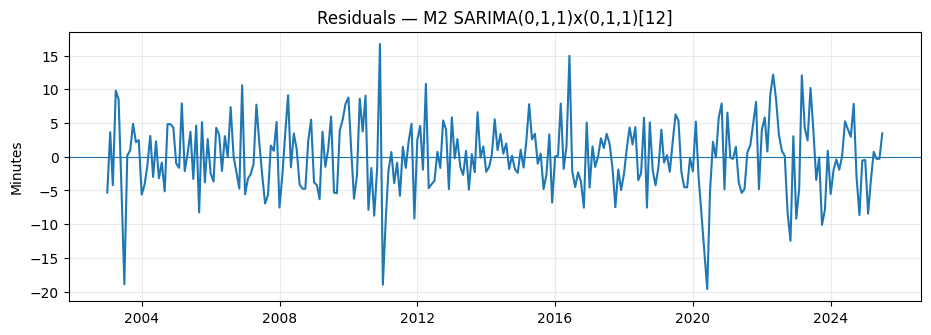

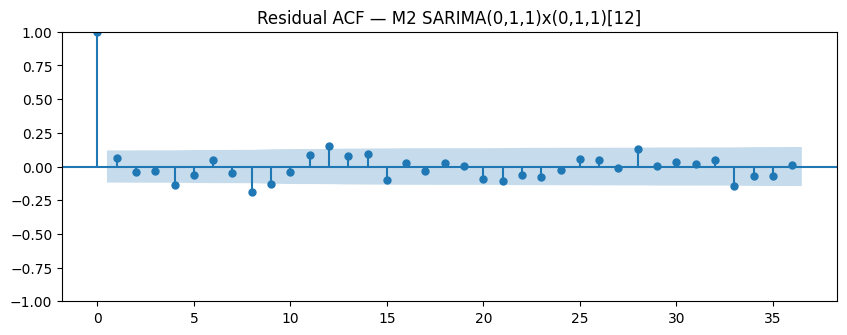

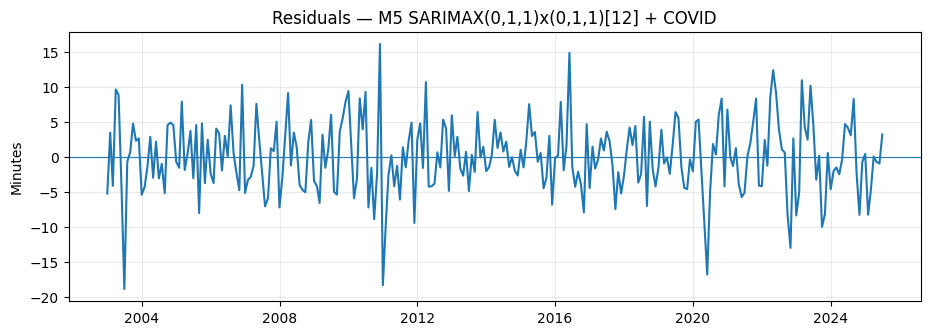

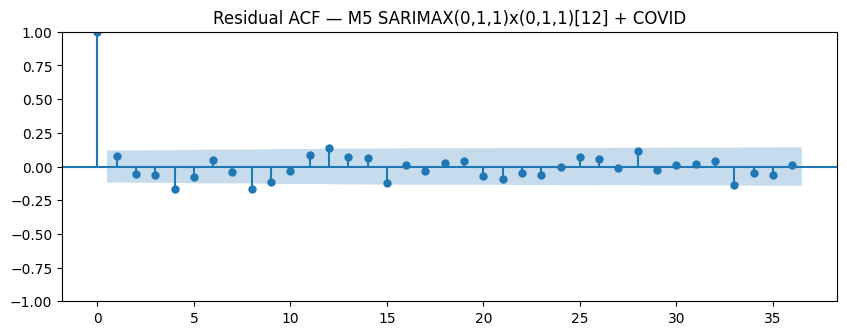

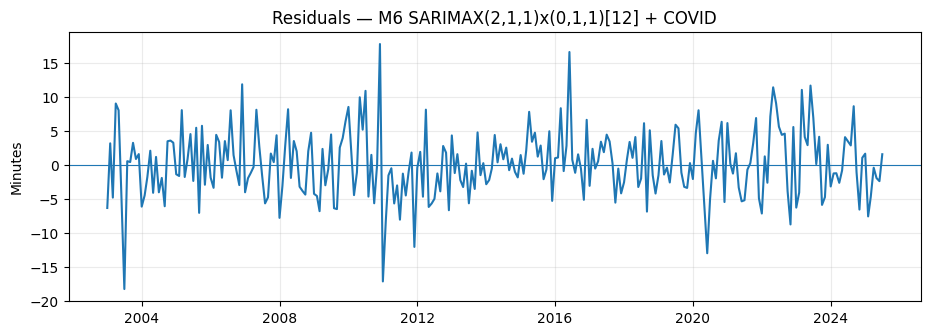

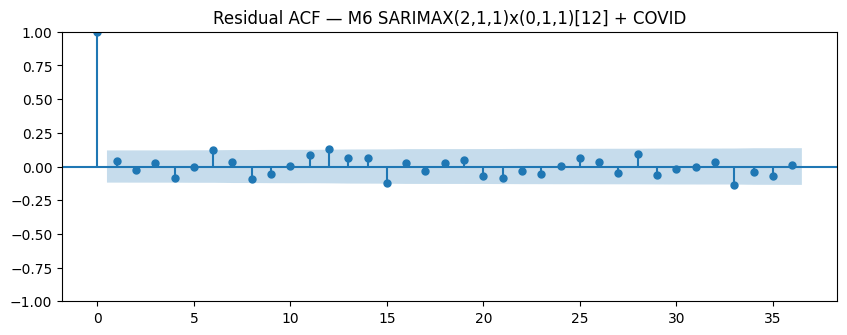

In [12]:

# Plot residual ACF for the three most informative candidates:
diagnostic_models = [
    "M2 SARIMA(0,1,1)x(0,1,1)[12]",
    "M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID",
    "M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID",
]

for name in diagnostic_models:
    fit = fits[name]
    resid = pd.Series(fit.resid, index=train.index).dropna().iloc[24:]

    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(resid)
    ax.axhline(0, linewidth=0.8)
    ax.set_title(f"Residuals — {name}")
    ax.set_ylabel("Minutes")
    ax.grid(alpha=0.25)
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 3.5))
    plot_acf(resid, lags=36, ax=ax)
    ax.set_title(f"Residual ACF — {name}")
    plt.show()



# 11. Preliminary holdout comparison

This plot is not intended to declare the final forecasting winner. It asks a simpler question:

> **Do the candidate models produce reasonable one-year forecasts, and do they improve on seasonal naïve?**

A model with excellent AIC but poor holdout accuracy should not be promoted automatically.


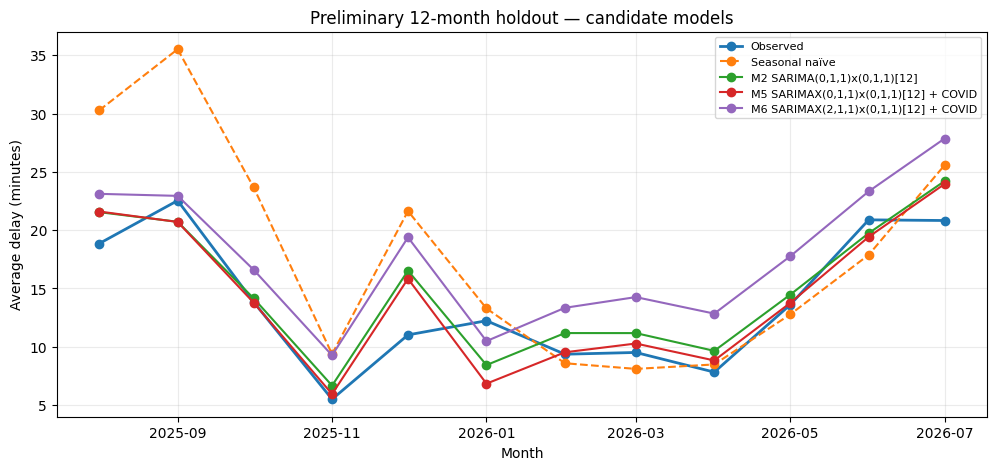

In [13]:

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(test.index, test, marker="o", linewidth=2, label="Observed")
ax.plot(
    test.index, seasonal_naive,
    marker="o", linestyle="--",
    label="Seasonal naïve"
)

for name in [
    "M2 SARIMA(0,1,1)x(0,1,1)[12]",
    "M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID",
    "M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID",
]:
    ax.plot(
        forecasts[name].index,
        forecasts[name],
        marker="o",
        label=name
    )

ax.set_title("Preliminary 12-month holdout — candidate models")
ax.set_ylabel("Average delay (minutes)")
ax.set_xlabel("Month")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
plt.show()



# 12. COVID sensitivity analysis

We now test whether one COVID dummy is sufficient.

### Model C1 — one regime dummy
March 2020–December 2021.

### Model C2 — two-stage intervention
- March–December 2020;
- January–December 2021.

### Model C3 — COVID masked
March 2020–December 2021 is set to missing **only during estimation** while the monthly calendar is preserved.

For C3, AIC/BIC are deliberately not used for cross-model ranking because the effective estimation sample differs.


In [14]:

covid_sensitivity = []

# C1 — one COVID regime
fit_c1, fc_c1, row_c1 = fit_candidate(
    name="C1 one COVID dummy",
    order=(0,1,1),
    seasonal_order=(0,1,1,12),
    trend="n",
    exog_cols=["covid_regime"],
)
covid_sensitivity.append(row_c1)

# C2 — two-stage COVID
fit_c2, fc_c2, row_c2 = fit_candidate(
    name="C2 two-stage COVID",
    order=(0,1,1),
    seasonal_order=(0,1,1,12),
    trend="n",
    exog_cols=["covid_2020", "covid_2021"],
)
covid_sensitivity.append(row_c2)

# C3 — mask COVID but preserve the calendar
train_masked = train.copy()
train_masked.loc["2020-03-01":"2021-12-01"] = np.nan

fit_c3, fc_c3, row_c3 = fit_candidate(
    name="C3 COVID masked",
    order=(0,1,1),
    seasonal_order=(0,1,1,12),
    trend="n",
    exog_cols=None,
    y_train=train_masked,
)

# AIC/AICc/BIC not comparable with full-sample models
row_c3["AIC"] = np.nan
row_c3["AICc"] = np.nan
row_c3["BIC"] = np.nan

covid_sensitivity.append(row_c3)

covid_table = pd.DataFrame(covid_sensitivity)
display(covid_table.round(3))


,Model,AIC,AICc,BIC,MAE,RMSE,LB p(12),LB p(24),ARCH-LM p,JB p,Converged
0,C1 one COVID dummy,"1,747.250","1,747.388","1,761.817",1.831,2.533,0.001,0.004,0.029,0.001,True
1,C2 two-stage COVID,"1,747.837","1,748.044","1,766.046",1.814,2.569,0.001,0.004,0.008,0.002,True
2,C3 COVID masked,NaN,NaN,NaN,3.831,4.579,0.027,0.169,0.027,0.018,True


In [15]:

print("One-dummy COVID coefficient:")
display(parameter_table(fit_c1, "C1").round(4))

print("\nTwo-stage COVID coefficients:")
display(parameter_table(fit_c2, "C2").round(4))


One-dummy COVID coefficient:


,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,C1,covid_regime,-8.210,3.379,0.015,-14.832,-1.587
1,C1,ma.L1,-0.417,0.051,0.000,-0.517,-0.317
2,C1,ma.S.L12,-0.877,0.049,0.000,-0.972,-0.781
3,C1,sigma2,27.329,1.925,0.000,23.556,31.102



Two-stage COVID coefficients:


,Model,Parameter,Estimate,Std. error,p-value,CI 2.5%,CI 97.5%
0,C2,covid_2020,-10.741,3.036,0.000,-16.692,-4.791
1,C2,covid_2021,-6.327,7.530,0.401,-21.086,8.433
2,C2,ma.L1,-0.419,0.051,0.000,-0.518,-0.320
3,C2,ma.S.L12,-0.871,0.048,0.000,-0.966,-0.777
4,C2,sigma2,27.236,1.895,0.000,23.522,30.950



### How to interpret the COVID comparison

Prefer a more complex intervention only if it contributes meaningful information.

Questions to ask:
1. Are the COVID coefficients statistically and substantively meaningful?
2. Does the two-stage version improve AIC/AICc/BIC relative to the one-dummy model?
3. Does it improve residual diagnostics?
4. Does it improve the holdout metrics?
5. Is the gain large enough to justify an extra parameter?

The masked version is a **robustness check**, not a direct AIC competitor.



# 13. Variance-stabilising transformation: sensitivity candidate

Deliverable 1 estimated a Box–Cox parameter close to $\lambda \approx 0.5$, suggesting a square-root-like transformation.

We therefore test one sensitivity model using:

$$
Z_t=\sqrt{Y_t}
$$

This candidate is **not** ranked by comparing its AIC directly with raw-scale models because the likelihoods are calculated on different response scales.

Instead, its forecasts are transformed back to minutes and compared using MAE and RMSE.

This section checks whether variance stabilisation improves forecasting enough to justify the additional interpretation complexity.


In [16]:

sqrt_y = np.sqrt(y)
sqrt_train = sqrt_y.loc[train.index]

sqrt_model = SARIMAX(
    sqrt_train,
    order=(0,1,1),
    seasonal_order=(0,1,1,12),
    trend="n",
    exog=interventions.loc[train.index, ["covid_regime"]],
    enforce_stationarity=True,
    enforce_invertibility=True,
)

sqrt_fit = sqrt_model.fit(disp=False, maxiter=500)

sqrt_fc = sqrt_fit.get_forecast(
    steps=len(test),
    exog=interventions.loc[test.index, ["covid_regime"]]
).predicted_mean

sqrt_fc.index = test.index

# Simple inverse transform for preliminary comparison.
# A formal final forecast may later consider transformation-bias correction.
sqrt_backtransformed = sqrt_fc**2

sqrt_metrics = forecast_metrics(test, sqrt_backtransformed)

display(pd.DataFrame([{
    "Candidate": "sqrt-SARIMAX(0,1,1)x(0,1,1)[12] + COVID",
    **sqrt_metrics
}]).round(3))


,Candidate,MAE,RMSE
0,"sqrt-SARIMAX(0,1,1)x(0,1,1)[12] + COVID",2.556,2.839



# 14. Should GARCH be carried forward?

GARCH models the **conditional variance**, not the conditional mean.

The forecasting target in this project is the **monthly mean delay**, so GARCH should not replace SARIMA/SARIMAX.

A GARCH extension is worth considering only if:

1. the mean model is adequately specified;
2. residual serial correlation has largely been removed;
3. the squared residuals / ARCH-LM still indicate volatility clustering.

The correct modelling order is:

<div align="center">

**Mean model** → **Residual autocorrelation check** → **Conditional-variance check** → **GARCH, only if justified**

</div>

If a candidate still fails the Ljung–Box test, improving the **mean dynamics** takes priority over fitting GARCH.



# 15. Candidate-selection matrix

The following table turns the statistical evidence into a transparent selection decision.

A candidate is **retained** when it adds a distinct and defensible modelling idea that deserves formal forecasting evaluation later.

It is **not necessary** that one model already be declared the final winner in Deliverable 2.


In [17]:

comparison = results_table.copy()

# Add simple readable flags.
comparison["Good LB12?"] = comparison["LB p(12)"].apply(
    lambda p: np.nan if pd.isna(p) else p > 0.05
)
comparison["Good LB24?"] = comparison["LB p(24)"].apply(
    lambda p: np.nan if pd.isna(p) else p > 0.05
)

display(
    comparison[
        ["Model", "AICc", "BIC", "MAE", "RMSE",
         "LB p(12)", "LB p(24)", "ARCH-LM p",
         "Good LB12?", "Good LB24?"]
    ].round(3)
)


,Model,AICc,BIC,MAE,RMSE,LB p(12),LB p(24),ARCH-LM p,Good LB12?,Good LB24?
0,B0 Seasonal naive,NaN,NaN,5.099,6.828,NaN,NaN,NaN,NaN,NaN
1,"M1 SARMA(1,0,1)x(1,0,1)[12]","1,813.962","1,835.792",3.015,3.482,0.028,0.028,0.045,False,False
2,"M2 SARIMA(0,1,1)x(0,1,1)[12]","1,750.645","1,761.488",2.166,2.577,0.001,0.001,0.175,False,False
3,"M3 SARIMA(1,1,1)x(0,1,1)[12]","1,750.085","1,764.515",2.817,3.260,0.064,0.019,0.137,True,False
4,"M4 SARIMA(2,1,1)x(0,1,1)[12]","1,741.977","1,759.979",2.627,3.037,0.029,0.033,0.142,False,False
5,"M5 SARIMAX(0,1,1)x(0,1,1)[12] + COVID","1,747.388","1,761.817",1.831,2.533,0.001,0.004,0.029,False,False
6,"M6 SARIMAX(2,1,1)x(0,1,1)[12] + COVID","1,732.580","1,754.139",4.056,4.557,0.149,0.199,0.012,True,True



## 16. Proposed models to carry into the forecasting stage

Based on the EDA logic and the diagnostics above, the following set is the most defensible to carry forward:

### Benchmark — Seasonal naïve
Must be retained as the minimum standard that a seasonal forecasting model should beat.

### Candidate A — SARIMA(0,1,1)×(0,1,1)$_{12}$
Retain as the **parsimonious seasonal ARIMA reference** directly suggested by the lag-1 and lag-12 structure after differencing.

### Candidate B — SARIMAX(0,1,1)×(0,1,1)$_{12}$ + COVID intervention
Retain as the **primary intervention candidate** because it separates exceptional pandemic behaviour from ordinary seasonal dynamics.

### Candidate C — SARIMAX(2,1,1)×(0,1,1)$_{12}$ + COVID intervention
Retain as a **richer short-memory alternative** if it materially improves residual whiteness, even if its holdout performance is not automatically best.

### Candidate D — non-differenced SARMA alternative
Keep only if the stationarity tests and diagnostics give it a credible role. If it is clearly dominated in fit, residual structure and forecasting error, it can be rejected before the final forecasting stage.

### COVID sensitivity
The two-stage COVID and COVID-masked specifications are **sensitivity analyses**, not separate final model families unless they clearly improve the evidence.

### Square-root sensitivity
Keep only if the back-transformed holdout errors improve meaningfully. Do not compare its AIC directly with raw-scale models.

### GARCH
Carry forward only as a **variance extension** if the selected mean model passes serial-correlation diagnostics but retains ARCH effects.

---

## What Deliverable 2 should conclude

The purpose of this deliverable is **not** to announce one definitive forecasting model.

The defensible conclusion is:

> The EDA motivates a seasonal model with both short-term and annual dependence. Formal stationarity tests justify comparing differenced and non-differenced formulations rather than imposing differencing automatically. The leading candidates are therefore a parsimonious seasonal ARIMA and COVID-intervention SARIMAX variants, with a richer short-memory specification retained when it materially improves residual diagnostics. Final model choice will be based on formal out-of-sample forecasting evaluation in the next stage.



## 17. Export tables for the professional report

The following files are optional but convenient when building the 3–4 page Deliverable 2 report.


In [18]:

results_table.to_csv("deliverable2_candidate_results.csv", index=False)
parameters.to_csv("deliverable2_candidate_parameters.csv", index=False)
roots_table.to_csv("deliverable2_candidate_roots.csv", index=False)
covid_table.to_csv("deliverable2_covid_sensitivity.csv", index=False)

print("Exported:")
print("- deliverable2_candidate_results.csv")
print("- deliverable2_candidate_parameters.csv")
print("- deliverable2_candidate_roots.csv")
print("- deliverable2_covid_sensitivity.csv")


Exported:
- deliverable2_candidate_results.csv
- deliverable2_candidate_parameters.csv
- deliverable2_candidate_roots.csv
- deliverable2_covid_sensitivity.csv
